# Блокнот 04: Просторово-часові зв'язки та маршрути загроз (RQ3)

**Дослідницьке питання (RQ3):**
> *Чи можна на основі взаємних часових затримок (lead-lag cross-correlation) між безпосередньо суміжними областями відновити типові просторово-часові ланцюжки поширення тривог («хвилі» підльоту), ізолювавши при цьому синхронні загальнонаціональні тривоги?*

У цьому блокноті досліджено:
1. Побудову графа фізичного сухопутного сусідства (49 пар суміжних областей України).
2. Дискретизацію часового ряду в 10-хвилинну бінарну сітку (235,487 точок з 2022 по 2026 рік).
3. Ізоляцію синхронних загальнонаціональних тривог (>= 15 областей одночасно, наприклад зльоти МіГ-31К).
4. Розрахунок крос-кореляції з лагами $\tau \in [-180, +180]$ хв та визначення Lead Time.
5. Побудову орієнтованого графа затримок.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

summary_path = Path("../reports/official/spatial_lead_lag_summary.csv")
routes_df = pd.read_csv(summary_path)
print(f"Завантажено результати аналізу для {len(routes_df)} пар суміжних областей.")
display(routes_df.head(10))

Завантажено результати аналізу для 49 пар суміжних областей.


,region_a,region_b,dominant_pair,direction_type,lead_time_min,max_correlation,correlation_lag0,joint_active_intervals
0,Херсонська область,Миколаївська область,Миколаївська область ➔ Херсонська область,Спрямоване випередження (B ➔ A),10,0.6576,0.6576,24128
1,Дніпропетровська область,Запорізька область,Дніпропетровська область ⟷ Запорізька область,Синхронне включення (< 10 хв),0,0.6130,0.6130,61487
2,Львівська область,Івано-Франківська область,Івано-Франківська область ➔ Львівська область,Спрямоване випередження (B ➔ A),10,0.6017,0.6017,504
3,Київська область,м. Київ,м. Київ ➔ Київська область,Спрямоване випередження (B ➔ A),10,0.5777,0.5777,10078
4,Чернігівська область,Сумська область,Чернігівська область ➔ Сумська область,Спрямоване випередження (A ➔ B),10,0.5742,0.5742,51028
5,Волинська область,Рівненська область,Волинська область ➔ Рівненська область,Спрямоване випередження (A ➔ B),10,0.5733,0.5733,1232
6,Черкаська область,Кіровоградська область,Черкаська область ➔ Кіровоградська область,Спрямоване випередження (A ➔ B),10,0.5699,0.5699,14621
7,Дніпропетровська область,Донецька область,Дніпропетровська область ➔ Донецька область,Спрямоване випередження (A ➔ B),10,0.5690,0.5690,75753
8,Тернопільська область,Івано-Франківська область,Івано-Франківська область ➔ Тернопільська область,Спрямоване випередження (B ➔ A),10,0.5591,0.5591,645
9,Житомирська область,Київська область,Житомирська область ➔ Київська область,Спрямоване випередження (A ➔ B),10,0.5477,0.5477,10367


## 1. Візуалізація топ ланцюжків поширення тривог (Lead-Lag Аналіз)

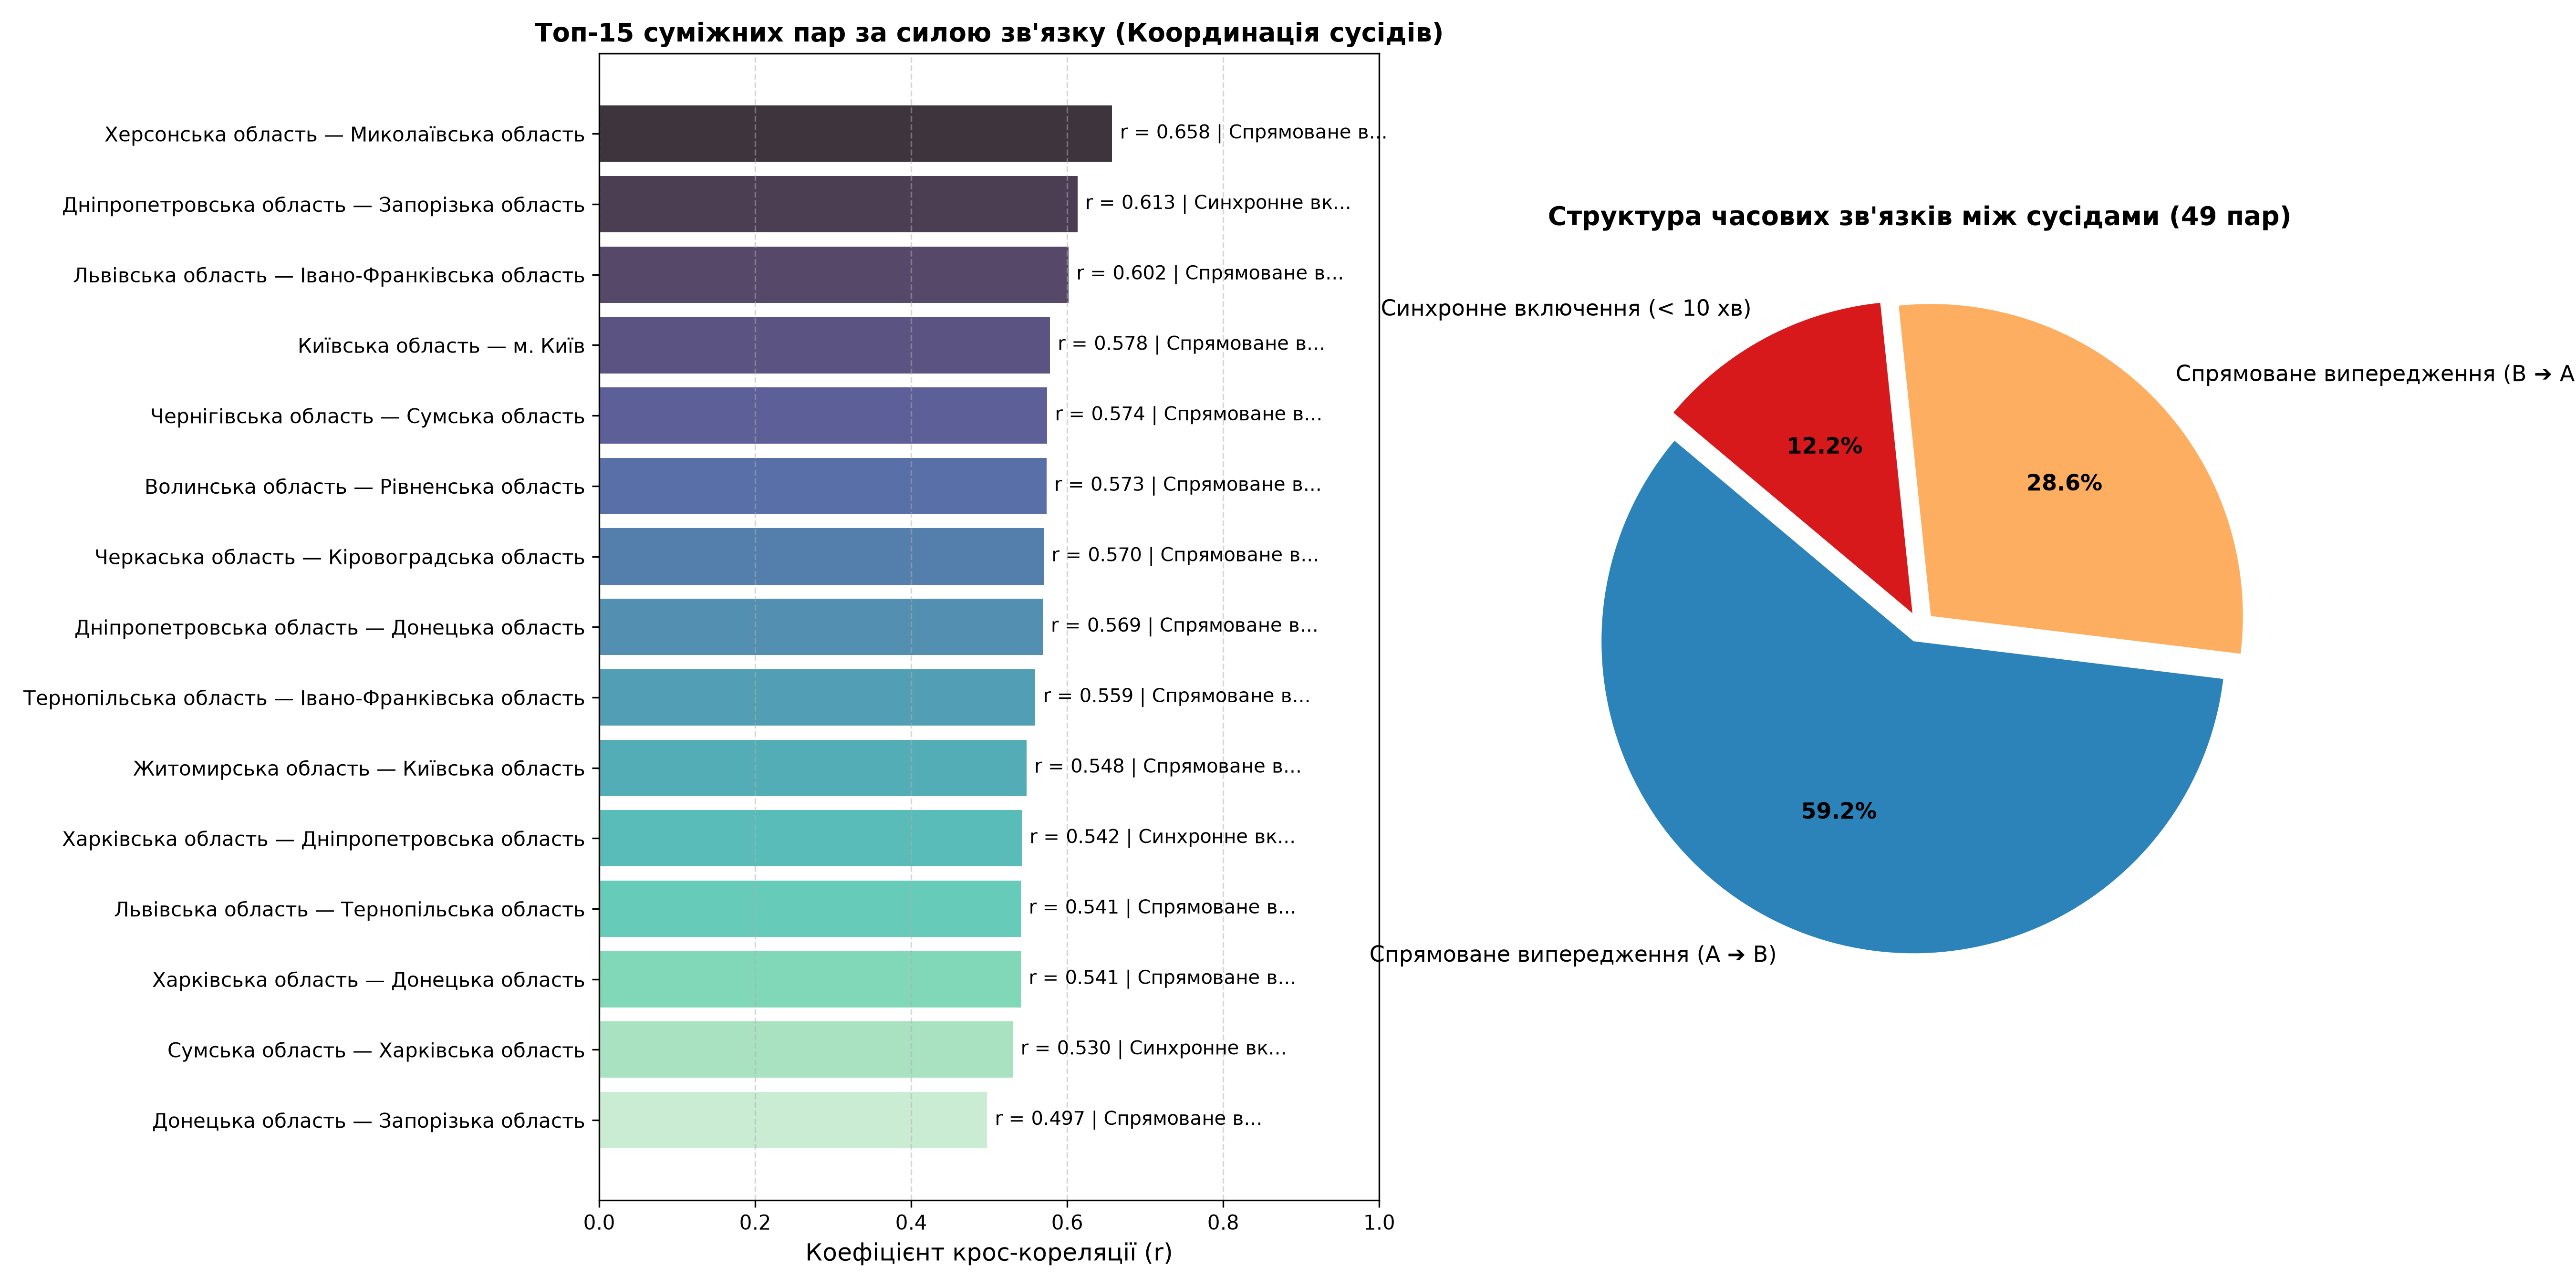

In [2]:
display(Image("../reports/official/figures/06_spatial_cross_correlation_routes.png"))

## 2. Найсильніші кореляції між сусідніми областями

In [3]:
print("Топ-10 найсильніших пар за рівнем кореляції:")
display(routes_df.sort_values("max_correlation", ascending=False).head(10))

Топ-10 найсильніших пар за рівнем кореляції:


,region_a,region_b,dominant_pair,direction_type,lead_time_min,max_correlation,correlation_lag0,joint_active_intervals
0,Херсонська область,Миколаївська область,Миколаївська область ➔ Херсонська область,Спрямоване випередження (B ➔ A),10,0.6576,0.6576,24128
1,Дніпропетровська область,Запорізька область,Дніпропетровська область ⟷ Запорізька область,Синхронне включення (< 10 хв),0,0.6130,0.6130,61487
2,Львівська область,Івано-Франківська область,Івано-Франківська область ➔ Львівська область,Спрямоване випередження (B ➔ A),10,0.6017,0.6017,504
3,Київська область,м. Київ,м. Київ ➔ Київська область,Спрямоване випередження (B ➔ A),10,0.5777,0.5777,10078
4,Чернігівська область,Сумська область,Чернігівська область ➔ Сумська область,Спрямоване випередження (A ➔ B),10,0.5742,0.5742,51028
5,Волинська область,Рівненська область,Волинська область ➔ Рівненська область,Спрямоване випередження (A ➔ B),10,0.5733,0.5733,1232
6,Черкаська область,Кіровоградська область,Черкаська область ➔ Кіровоградська область,Спрямоване випередження (A ➔ B),10,0.5699,0.5699,14621
7,Дніпропетровська область,Донецька область,Дніпропетровська область ➔ Донецька область,Спрямоване випередження (A ➔ B),10,0.5690,0.5690,75753
8,Тернопільська область,Івано-Франківська область,Івано-Франківська область ➔ Тернопільська область,Спрямоване випередження (B ➔ A),10,0.5591,0.5591,645
9,Житомирська область,Київська область,Житомирська область ➔ Київська область,Спрямоване випередження (A ➔ B),10,0.5477,0.5477,10367


## 3. Важливе методологічне розмежування

> **Застереження:** Даний граф відображає **статистичну послідовність оголошення офіційних сповіщень**, а не фізичну радіолокаційну траєкторію повітряного судна чи ракети. Розрахований Lead Time показує середню затримку увімкнення сирени між сусідніми областями при проходженні локальних хвиль загроз.